In [96]:
#1. 라이브러리 불러오기 & 데이터 불러오기 
import pandas as pd,numpy as np
# Kaggle 경로 자동 탐색 (로컬이면 ../data)
import os, glob
cands = glob.glob('/kaggle/input/**/train.csv', recursive=True)
DATA = os.path.dirname(cands[0]) if cands else '../data'
import matplotlib.pyplot as plt, seaborn as sb 
train =pd.read_csv(f'{DATA}/train.csv')
test = pd.read_csv(f'{DATA}/test.csv')

train.info()


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [97]:
#2 데이터 구조 파악  
#2-1 Feature를 수치형, 명목형으로 나누기 (ID, Target 제외)
features = train.drop(columns=['Id', 'SalePrice'])

num_cols = features.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = features.select_dtypes(include=['object']).columns.tolist()

#MSSubClass, MoSold, YrSold은 수치형이지만 명목형으로 취급해야 함
# MSSubClass(건물 유형), MoSold(판매 월), YrSold(판매 연도)는 숫자지만 명목형
to_cat = ['MSSubClass', 'MoSold', 'YrSold']
num_cols = [c for c in num_cols if c not in to_cat]
cat_cols = cat_cols + [c for c in to_cat if c not in cat_cols]

for c in to_cat:
    train[c] = train[c].astype(str)
    test[c] = test[c].astype(str)

print(len(num_cols), "개의 수치형 Feature")
print(len(cat_cols), "개의 명목형 Feature")


33 개의 수치형 Feature
46 개의 명목형 Feature


In [98]:
# 2-2a SalesPrice의 분포 확인
train['SalePrice'].describe()



count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Text(0, 0.5, 'Frequency')

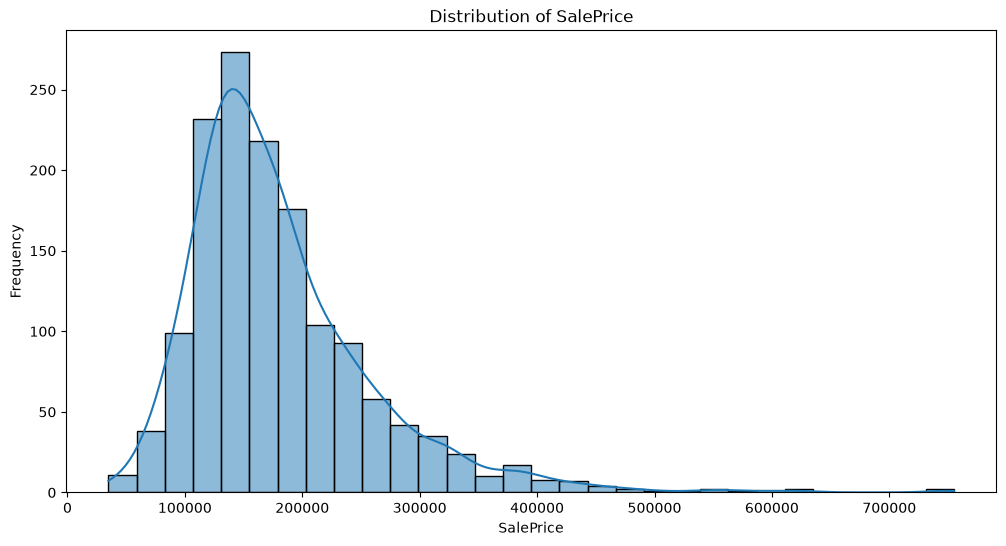

In [99]:
# 2-2b SalesPrice의 분포 그래프
plt.figure(figsize=(12, 6))
sb.histplot(train['SalePrice'], bins=30, kde=True)
plt.title('Distribution of SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Frequency')

# right-skewed (mean value approx. 180000 > median value 163000)
# outliers making mean value higher
# median value가 mean보다 보통 집값으로 말하기 적합할듯

In [100]:
#2-2c 왜도(Skewness)와 첨도(Kurtosis) 확인
print('왜도(Skewness):', train['SalePrice'].skew())   # 1.88 = 오른쪽으로 너무 많이 치우침
print('첨도(Kurtosis):', train['SalePrice'].kurt())   # 6.54 = 꼬리의 두께 극단적인 값의 빈도수가 높음 

# outliers의 값의 영향을 줄이기 위해서 로그변환 필요해보임


왜도(Skewness): 1.8828757597682129
첨도(Kurtosis): 6.536281860064529


In [101]:
#2-3a 수치형 Feature 분석

train[num_cols].describe().T

#결측치 존재:LotFrontage,MasVnrArea,GarageYrBlt  
#outlier 존재 : LotFrontage, LotArea, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, GrLivArea, GarageArea


,count,mean,std,min,25%,50%,75%,max
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0


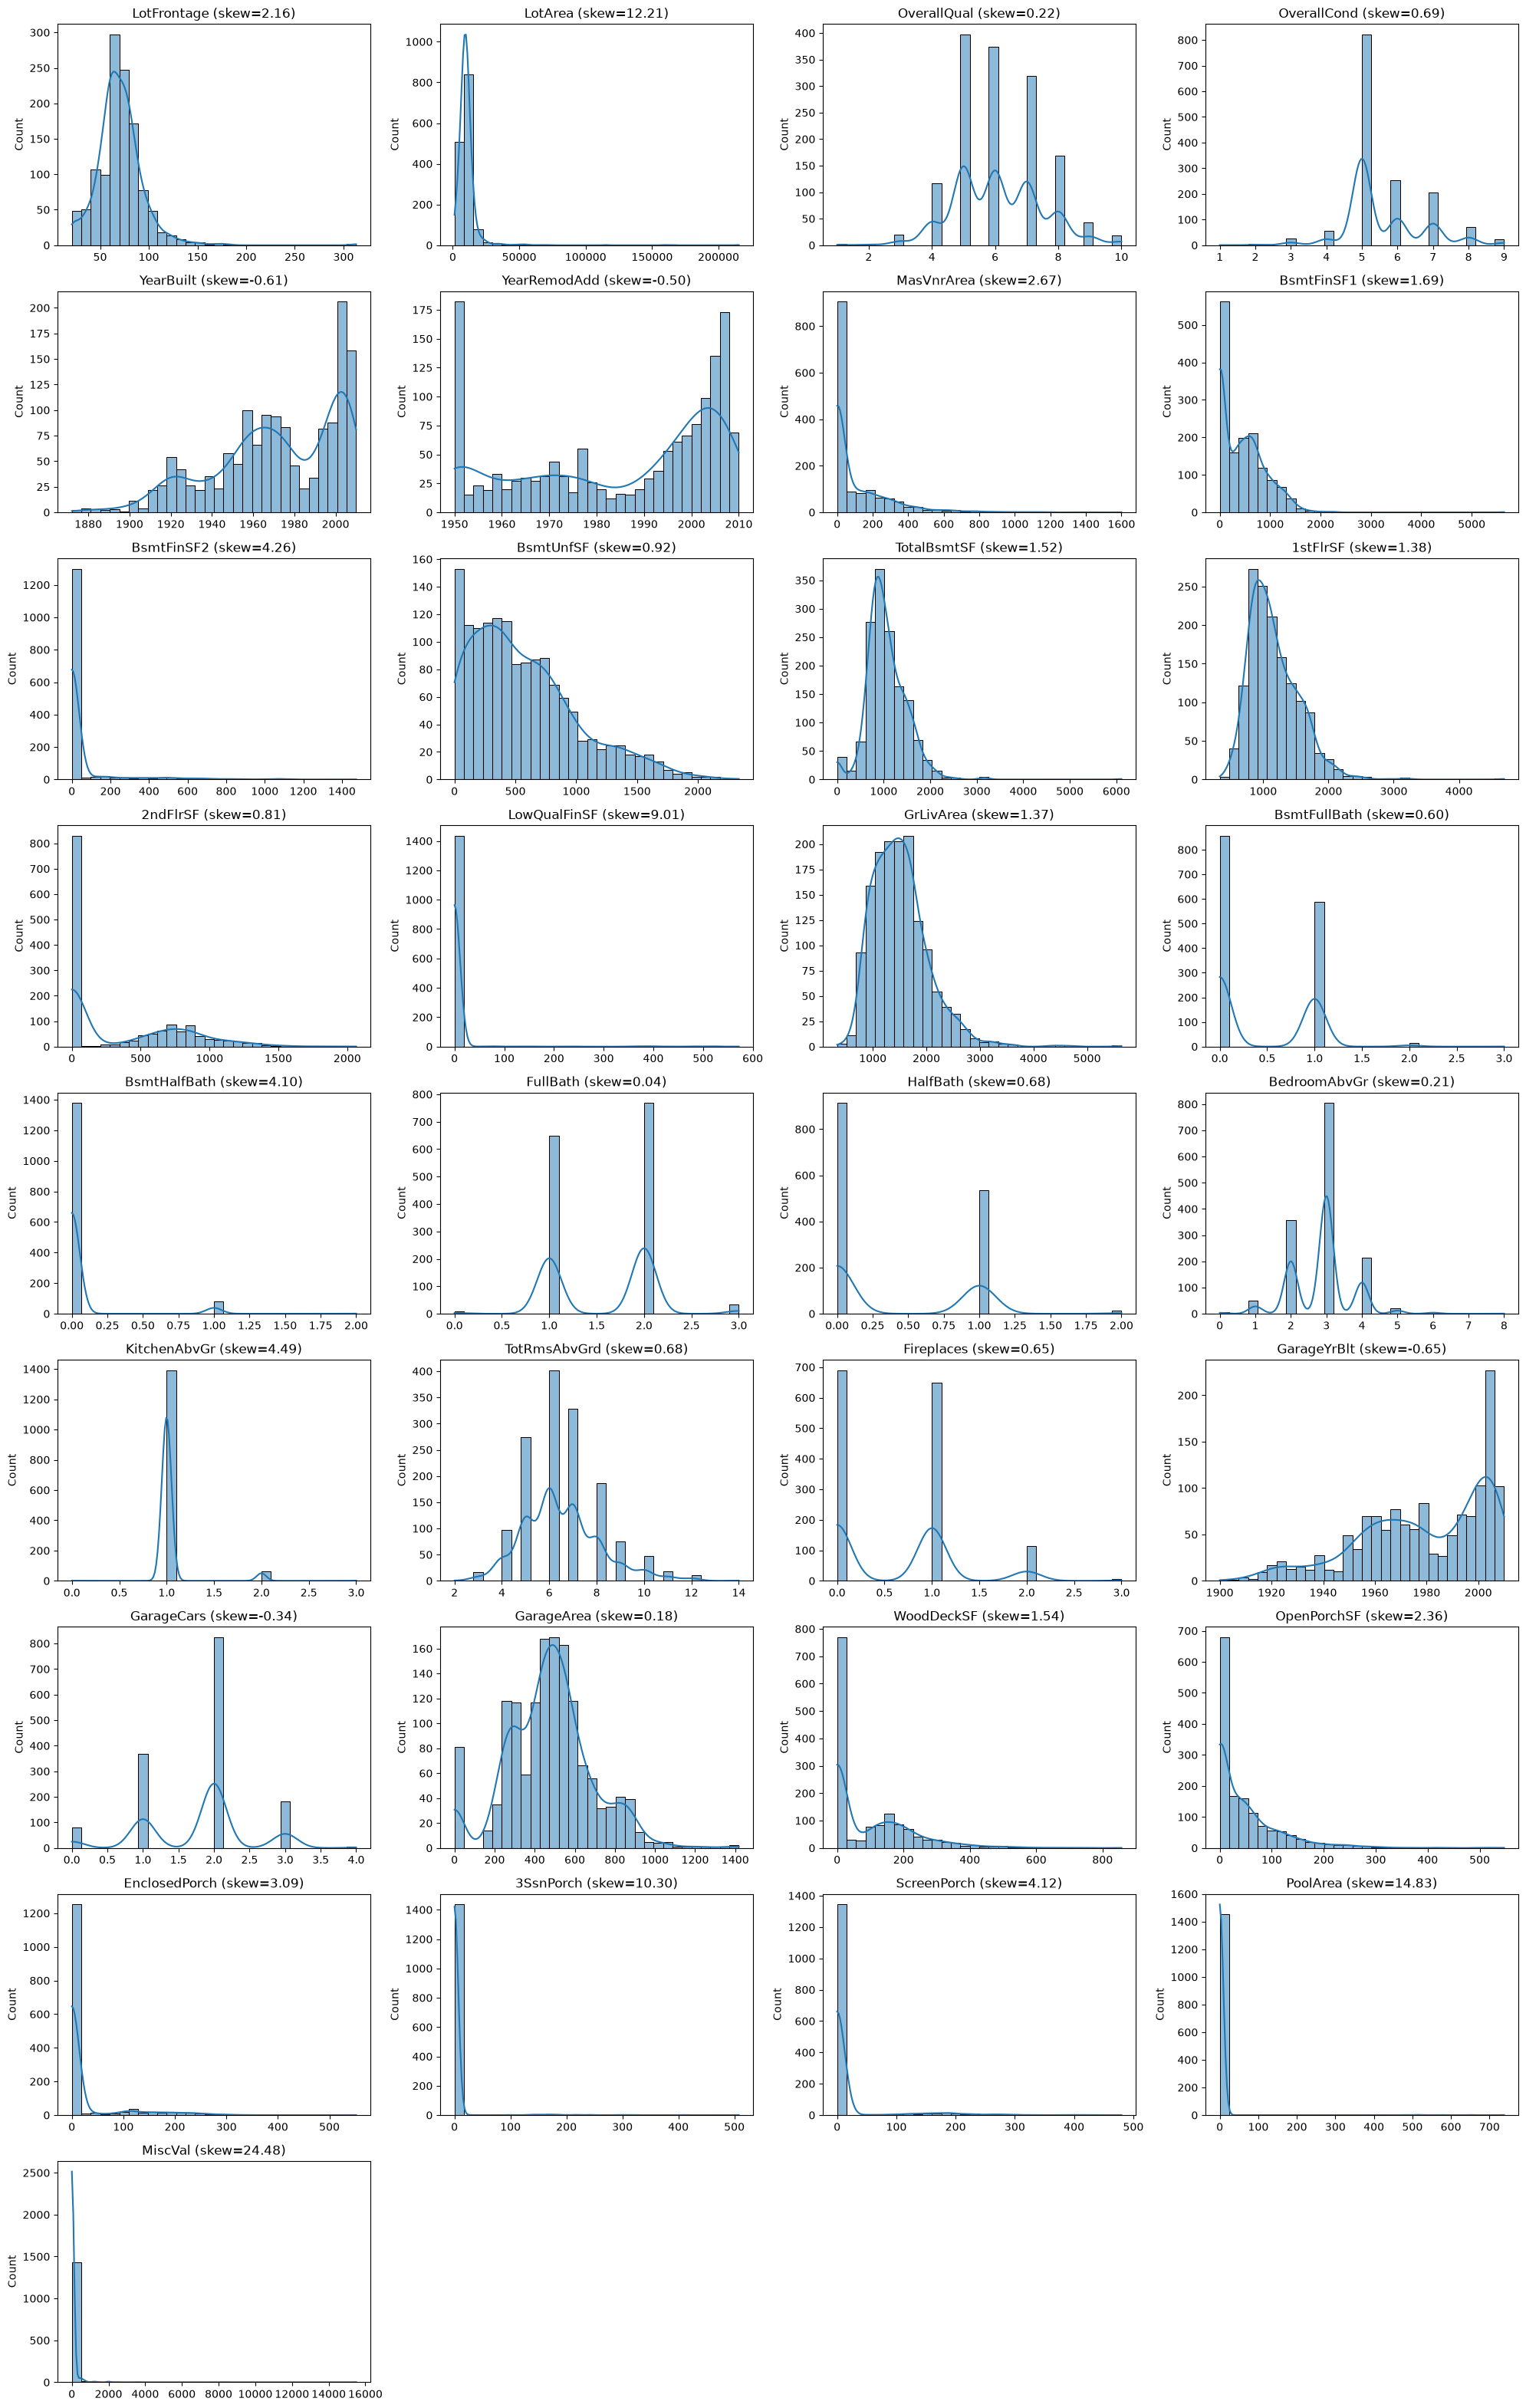

In [102]:
#2-3b 수치형 Feature 분포 그래프

n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))   # 33개 → 9줄

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()   # 2차원 격자를 1차원으로 펴서 하나씩 접근

for i, col in enumerate(num_cols):
    sb.histplot(train[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'{col} (skew={train[col].skew():.2f})')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):   # 남는 빈 칸 지우기
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# 로그 변환: LotArea, LotFrontage, BsmtFinSF1, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, GrLivArea
# 이진화(대부분 0): PoolArea, MiscVal, 3SsnPorch, LowQualFinSF, BsmtFinSF2, ScreenPorch, EnclosedPorch
# 이진 + 원래 값 유지: 2ndFlrSF, MasVnrArea, WoodDeckSF, OpenPorchSF, TotalBsmtSF(0=없음), GarageArea(0=없음)
# 개수·등급형(KDE 무시): FullBath, HalfBath, Bedroom, Fireplaces, GarageCars, TotRms, OverallQual/Cond
# 정보 적음: KitchenAbvGr(거의 1), OverallCond(대부분 5)
# 주의: YearRemodAdd 1950은 1950년 이전 기록이 잘린 값

In [103]:
#2-4a 명목형 Feature 분석
train[cat_cols].describe().T

# 결측치 존재: Alley, MasVnrType, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Electrical, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PoolQC, Fence, MiscFeature


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


IndexError: index 36 is out of bounds for axis 0 with size 36

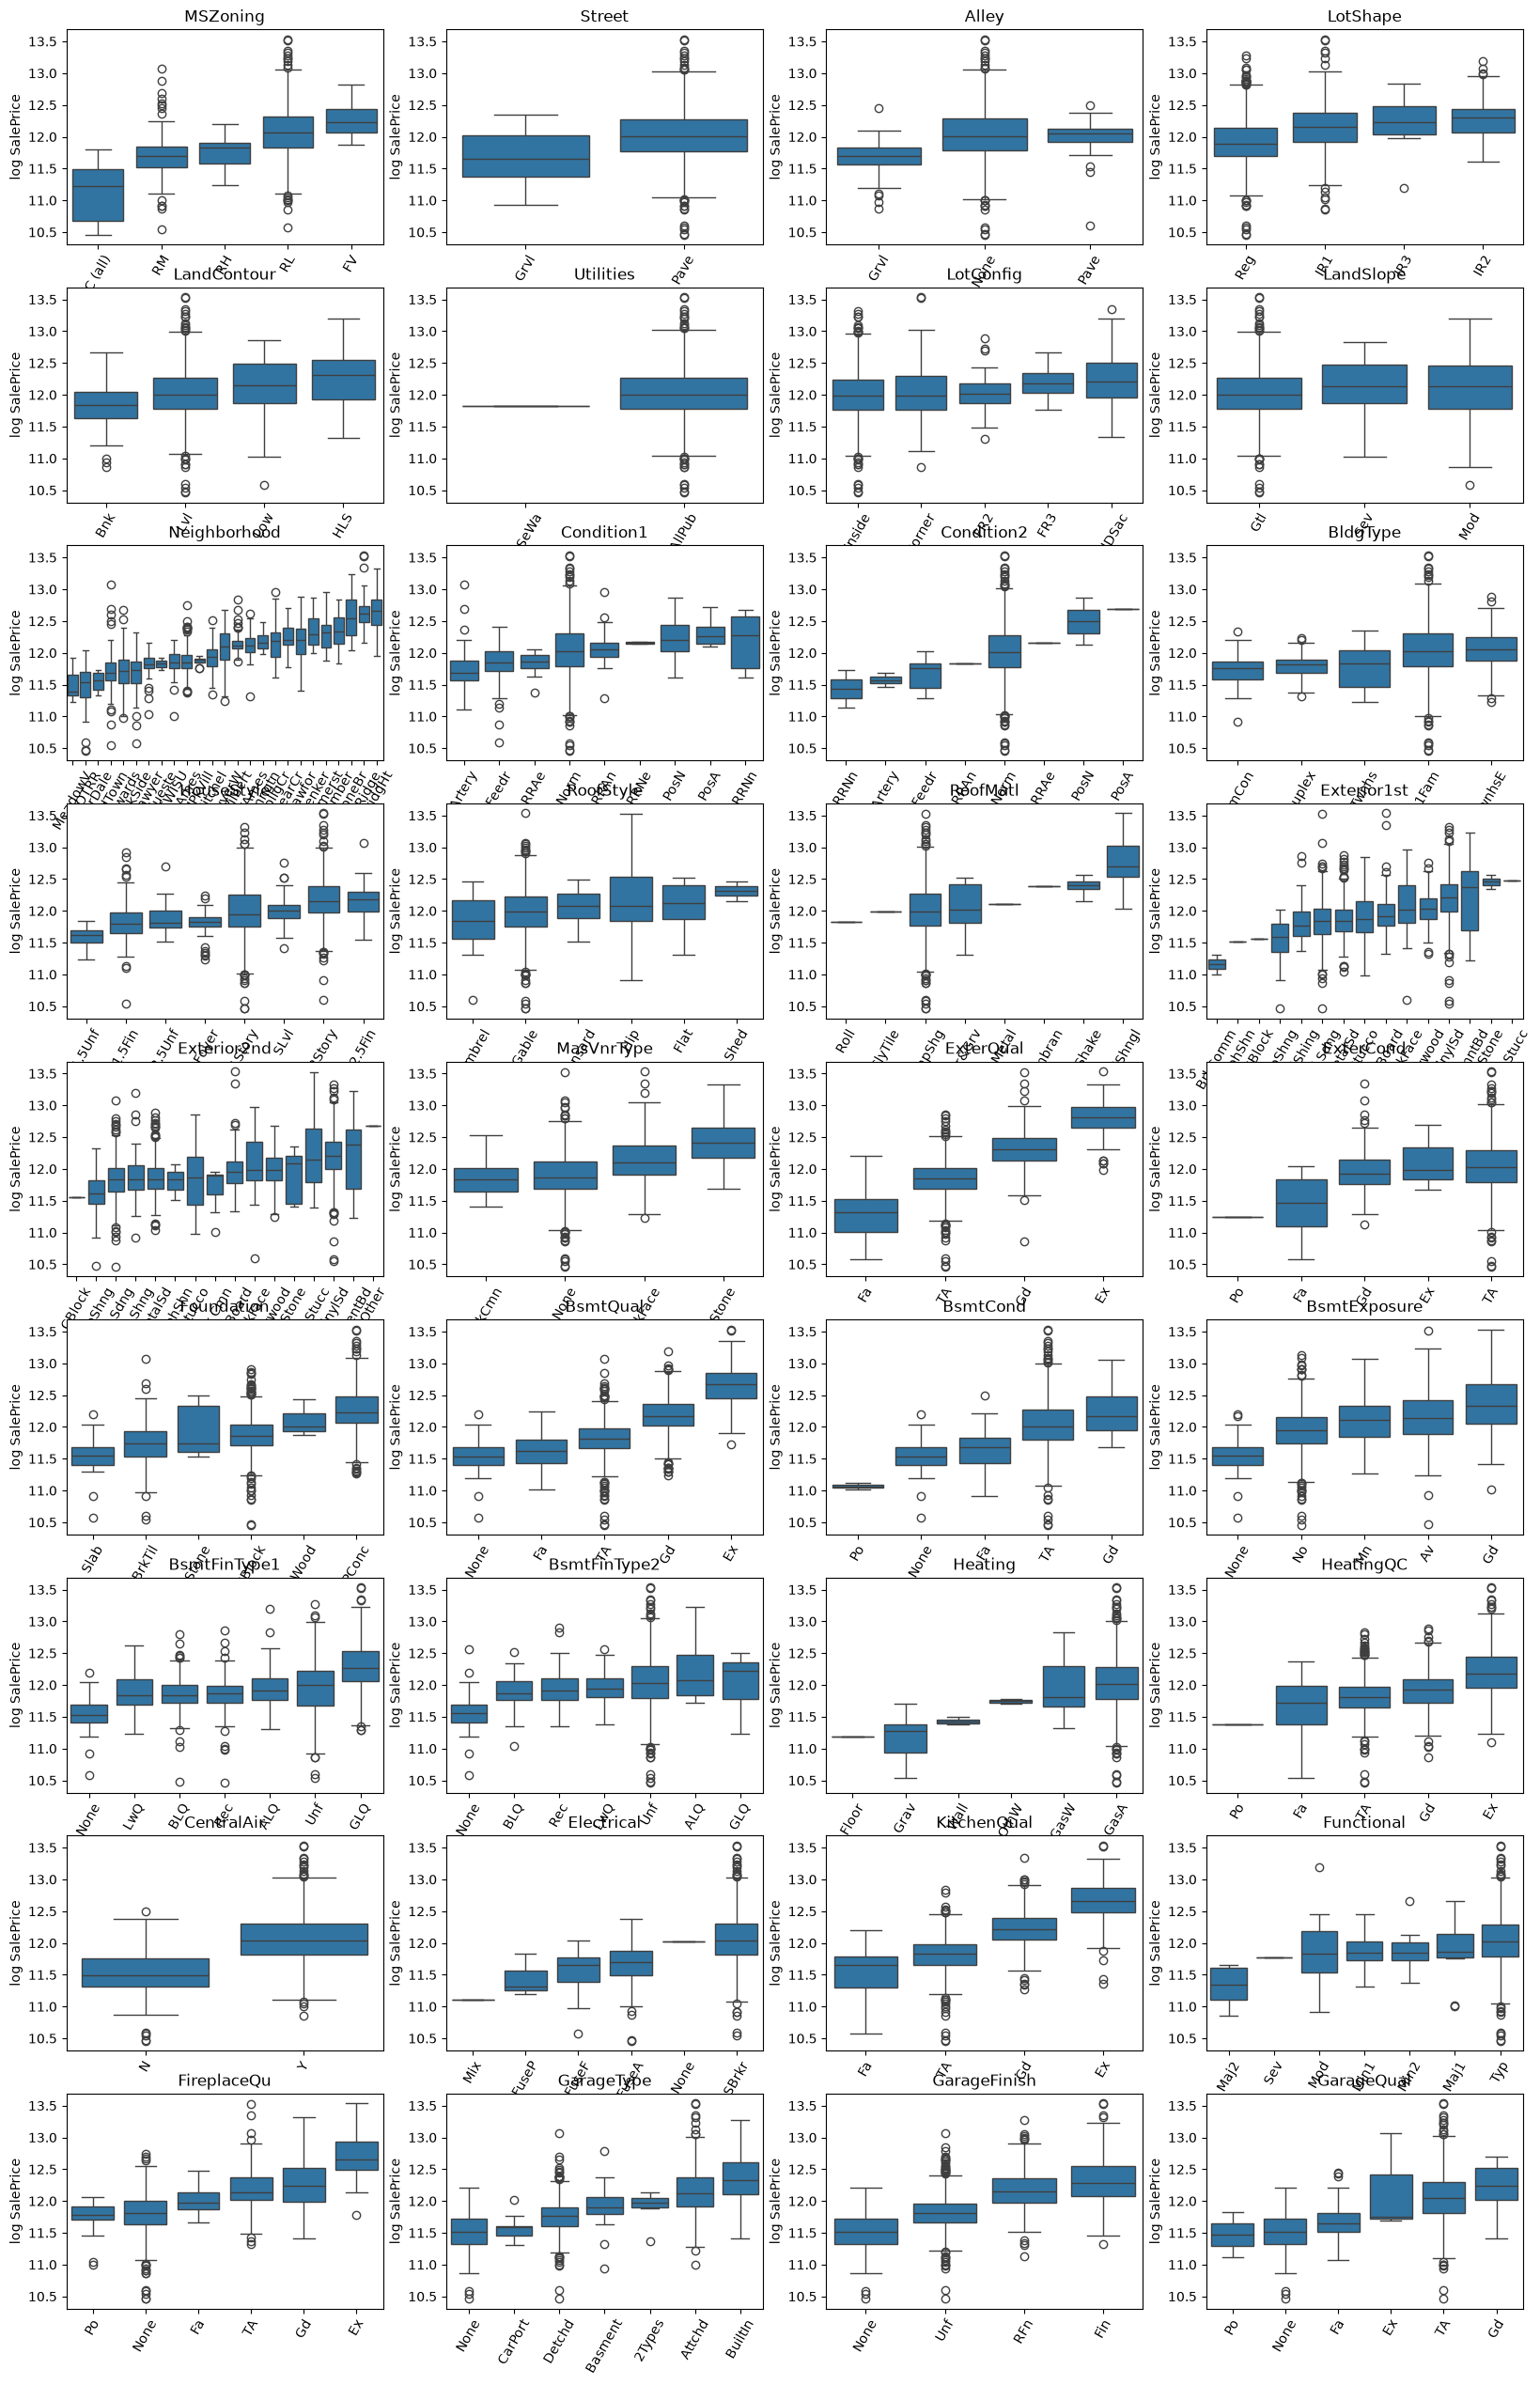

In [104]:
#2-4b 명목형 Feature 분포 그래프

cat_df = train[cat_cols].fillna('None')
log_price = np.log1p(train['SalePrice'])

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = log_price.groupby(cat_df[col]).median().sort_values().index   # 가격 순 정렬
    sb.boxplot(x=cat_df[col], y=log_price, order=order, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('log SalePrice')
    axes[i].tick_params(axis='x', rotation=60)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# 가격 관련 강함: ExterQual, KitchenQual, BsmtQual, FireplaceQu, HeatingQC, GarageFinish,
#               Neighborhood, MSZoning, Foundation, GarageType, MasVnrType, CentralAir
# 순서형 인코딩 적합(계단 깔끔): ExterQual, KitchenQual, BsmtQual, FireplaceQu, HeatingQC, GarageFinish, BsmtExposure
# 순서가 어긋남 → 명목형 유지: ExterCond, BsmtFinType1
# 가격 관련 약함: LotConfig, LandSlope, BldgType, RoofStyle
# 희귀 범주 많음(박스 신뢰 X): Utilities, Condition2, RoofMatl, Heating → 묶거나 제거
# None(시설 없음)은 대부분 가장 낮음 → 결측을 'None' 범주로 채운 게 맞음

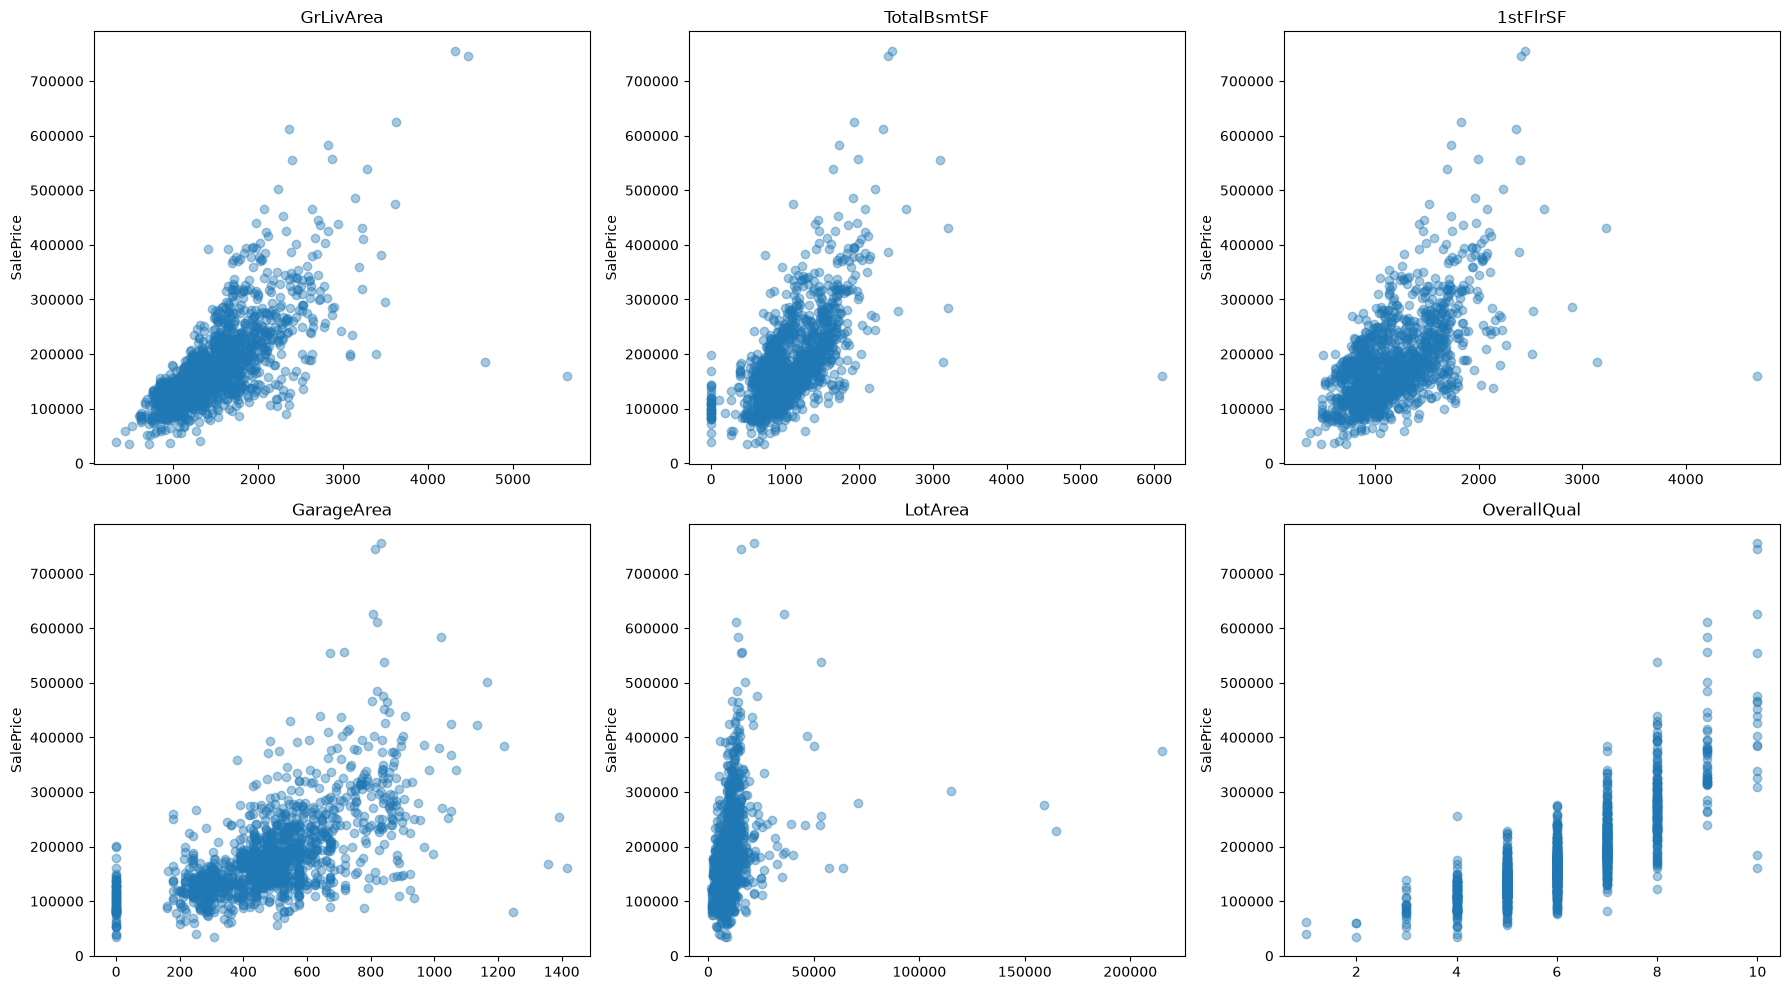

In [ ]:
#2-5 Outlier 확인 
cols = ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea', 'LotArea', 'OverallQual']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].scatter(train[col], train['SalePrice'], alpha=0.4)
    axes[i].set_title(col)
    axes[i].set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

# 이상치 제거: Id 524, 1299
#  - GrLivArea 대비 가격이 비정상적으로 낮음 (오른쪽 아래)
#  - Id 1299는 TotalBsmtSF, 1stFlrSF에서도 동떨어진 점
#  - 둘 다 OverallQual 10인데 가격은 하위권, SaleCondition = Partial
# 유지: Id 692, 1183 (크고 비싼 집, 추세를 따름)
# LotArea 극단값은 가격이 정상 → 제거 X, 로그 변환

In [ ]:
#3 전처리  

#3-1 Salesprice 로그변환 + 이상치 제거 + train/test 합치기

# 1. 이상치 제거
train = train[~train['Id'].isin([524, 1299])].reset_index(drop=True)

# 타깃은 로그 변환해서 따로 보관, 제출용 test Id도 보관 
y = np.log1p(train['SalePrice'])
test_id = test['Id']

# 2. train과 test 합치기
n_train = len(train)
all_data = pd.concat([train.drop(columns=['Id', 'SalePrice']),
                      test.drop(columns=['Id'])]).reset_index(drop=True)

print(all_data.shape)   # (2917, 79)

# 합친 데이터의 결측 현황
na = all_data.isnull().sum()
na[na > 0].sort_values(ascending=False)

(2917, 79)


PoolQC          2908
MiscFeature     2812
Alley           2719
Fence           2346
MasVnrType      1766
FireplaceQu     1420
LotFrontage      486
GarageQual       159
GarageYrBlt      159
GarageCond       159
GarageFinish     159
GarageType       157
BsmtExposure      82
BsmtCond          82
BsmtQual          81
BsmtFinType2      80
BsmtFinType1      79
MasVnrArea        23
MSZoning           4
BsmtFullBath       2
Functional         2
BsmtHalfBath       2
Utilities          2
BsmtFinSF1         1
Exterior2nd        1
Exterior1st        1
Electrical         1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64

In [ ]:
#3-2 결측치 처리
# (1) NA = "시설 없음"인 명목형 → 'None'
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
for c in none_cols:
    all_data[c] = all_data[c].fillna('None')

# (2) 시설이 없으면 면적·개수도 0인 수치형 → 0
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for c in zero_cols:
    all_data[c] = all_data[c].fillna(0)

# (3) 값을 추정해야 하는 컬럼
# 차고 연도: 차고가 없으면 집 건축 연도로 채움 (0으로 채우면 '0년에 지은 차고'가 됨)
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(all_data['YearBuilt'])

# 도로 접면 길이: 같은 동네 집들은 대지 모양이 비슷하므로 동네별 중앙값으로 채움
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'] \
                                  .transform(lambda s: s.fillna(s.median()))

# (4) 결측이 1~4개뿐인 컬럼 → 가장 흔한 값
all_data['Functional'] = all_data['Functional'].fillna('Typ')   # 설명서상 기본값이 Typ

mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd',
             'SaleType', 'Utilities']
for c in mode_cols:
    all_data[c] = all_data[c].fillna(all_data[:n_train][c].mode()[0])

print('남은 결측:', all_data.isnull().sum().sum())   # 0이 나와야 함

남은 결측: 0


In [ ]:
#3-3 Feature 변환 

#3-3a 불필요한 컬럼 제거+ 타입정리

# 거의 전부 AllPub이라 정보 없음
all_data = all_data.drop(columns=['Utilities'])

# 숫자지만 명목형인 컬럼 (앞에서 train만 바꿨을 수 있으니 all_data에 다시 적용)
for c in ['MSSubClass', 'MoSold', 'YrSold']:
    all_data[c] = all_data[c].astype(str)

In [ ]:
#3-3b 순서형 인코딩

qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for c in ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu', 'HeatingQC']:
    all_data[c] = all_data[c].map(qual_map)

all_data['GarageFinish'] = all_data['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
all_data['BsmtExposure'] = all_data['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})

In [ ]:
#3-3c 파생 변수 만들기 

# 총면적, 총 욕실 수
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalBath'] = (all_data['FullBath'] + 0.5 * all_data['HalfBath']
                         + all_data['BsmtFullBath'] + 0.5 * all_data['BsmtHalfBath'])

# 건물 나이, 리모델링 후 경과 연수 (음수는 0으로)
all_data['HouseAge'] = (all_data['YrSold'].astype(int) - all_data['YearBuilt']).clip(lower=0)
all_data['RemodAge'] = (all_data['YrSold'].astype(int) - all_data['YearRemodAdd']).clip(lower=0)

# 현관·데크 총면적
all_data['TotalPorchSF'] = (all_data['OpenPorchSF'] + all_data['EnclosedPorch']
                            + all_data['3SsnPorch'] + all_data['ScreenPorch'] + all_data['WoodDeckSF'])

# 시설 유무 이진 변수
for c in ['PoolArea', '2ndFlrSF', 'GarageArea', 'TotalBsmtSF', 'MasVnrArea', 'Fireplaces']:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)

In [ ]:
#3-3c-1 이진화: 대부분 0인 컬럼 → 유무만 남기고 원래 값은 제거
binary_only = ['PoolArea', 'MiscVal', '3SsnPorch', 'LowQualFinSF',
               'BsmtFinSF2', 'ScreenPorch', 'EnclosedPorch']
for c in binary_only:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)
all_data = all_data.drop(columns=binary_only)

# 이진 + 원래 값 유지
for c in ['WoodDeckSF', 'OpenPorchSF']:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)

In [ ]:
#3-3c-2 희귀 범주 묶기: train에서 10채 미만인 범주는 'Other'로
for c in ['Condition2', 'RoofMatl', 'Heating']:
    counts = all_data[:n_train][c].value_counts()
    keep = counts[counts >= 10].index
    all_data[c] = all_data[c].where(all_data[c].isin(keep), 'Other')
    print(c, all_data[c].value_counts().to_dict())

Condition2 {'Norm': 2888, 'Other': 29}
RoofMatl {'CompShg': 2875, 'Tar&Grv': 23, 'Other': 19}
Heating {'GasA': 2872, 'GasW': 27, 'Other': 18}


In [ ]:
#3-3d 로그 변환

log_cols = ['LotArea', 'LotFrontage', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF',
            '1stFlrSF', 'GrLivArea', 'TotalSF', 'MasVnrArea', 'TotalPorchSF']
for c in log_cols:
    all_data[c] = np.log1p(all_data[c])

In [ ]:
#3-3e 원-핫 인코딩 + 다시 나누기 

all_data = pd.get_dummies(all_data).astype(float)
print(all_data.shape)   # (2917, 314)

X = all_data[:n_train]
X_test = all_data[n_train:]
print(X.shape, X_test.shape)   # (1458, 314) (1459, 314)

(2917, 302)
(1458, 302) (1459, 302)


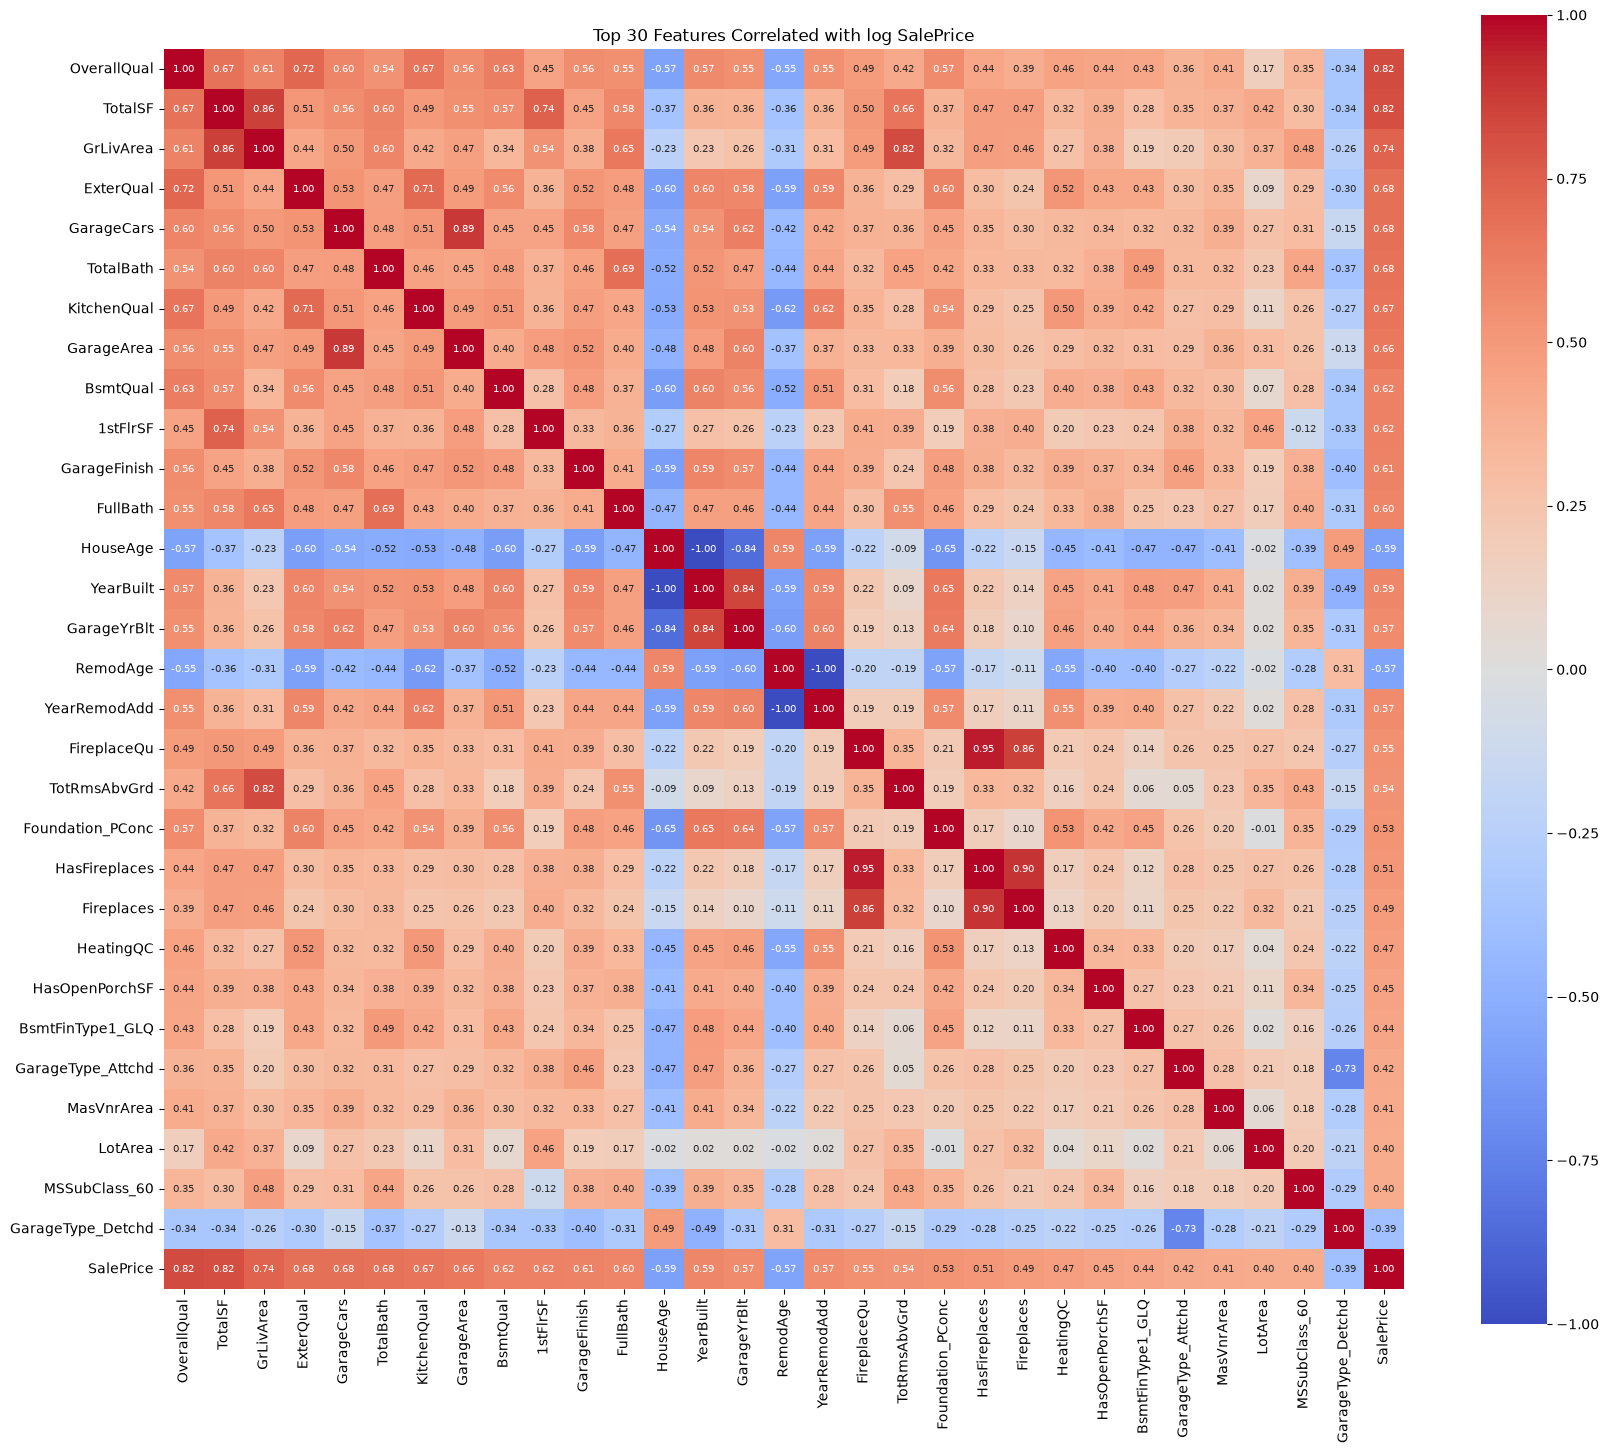

In [ ]:
#2-6 Feature 간 상관관계 확인

df = X.copy()
df['SalePrice'] = y.values

corr = df.corr()['SalePrice'].drop('SalePrice')
top = corr.abs().sort_values(ascending=False).head(30).index.tolist()

plt.figure(figsize=(20, 17))
sb.heatmap(df[top + ['SalePrice']].corr(), annot=True, fmt='.2f',
           cmap='coolwarm', vmin=-1, vmax=1, square=True,
           annot_kws={'size': 7})
plt.title('Top 30 Features Correlated with log SalePrice')
plt.show()



### 3-4. 상관관계 분석 (전처리 후, Top 30)

#### 1 SalePrice와 상관이 높은 피처
- 1위권(0.8 이상): OverallQual 0.82, TotalSF 0.82
- 0.6~0.75: GrLivArea 0.74, ExterQual / GarageCars / TotalBath 0.68, KitchenQual 0.67,
  GarageArea 0.66, BsmtQual / 1stFlrSF 0.62, GarageFinish 0.61, FullBath 0.60
- 집값을 결정하는 큰 축은 크게 4가지
  - 품질: OverallQual, ExterQual, KitchenQual, BsmtQual, HeatingQC, FireplaceQu
  - 크기: TotalSF, GrLivArea, 1stFlrSF, TotRmsAbvGrd, TotalBath
  - 연식: HouseAge, YearBuilt, RemodAge, YearRemodAdd
  - 차고: GarageCars, GarageArea, GarageFinish, GarageType

#### 2 음의 상관 (값이 클수록 싸짐)
- HouseAge −0.59, RemodAge −0.57: 오래된 집, 리모델링한 지 오래된 집일수록 저렴
- GarageType_Detchd −0.39: 차고가 집과 떨어져 있으면 저렴 (Attchd는 +0.42)

#### 3 전처리 효과 확인
- Top 30 중 파생·변환 피처가 다수 포함
  - 파생 변수: TotalSF(2위), TotalBath, HouseAge, RemodAge
  - 순서형 인코딩: ExterQual, KitchenQual, BsmtQual, GarageFinish, FireplaceQu, HeatingQC
    → 원래 문자열이라 상관계수를 계산할 수 없던 컬럼들이 상위권 진입
  - 이진화: HasFireplaces 0.51, HasOpenPorchSF 0.45
    → OpenPorchSF(면적)는 Top 30 밖이었지만, 유무로 바꾸니 0.45
    → 면적보다 '있다/없다' 자체가 가격과 관련
  - 원-핫: Foundation_PConc 0.53, BsmtFinType1_GLQ 0.44, MSSubClass_60 0.40
- TotalSF(0.82)가 원래 최상위 면적 피처인 GrLivArea(0.74)보다 높음
  → 지하·1층·2층을 합친 총면적이 가격을 더 잘 설명

#### 4 다중공선성 (피처끼리 |r| ≥ 0.8)
- −1.00: HouseAge-YearBuilt, RemodAge-YearRemodAdd
  → YrSold 범위가 2006~2010으로 좁아서 사실상 같은 정보
- 0.95 / 0.90 / 0.86: FireplaceQu-HasFireplaces-Fireplaces
  → 벽난로가 없으면 셋 다 0, 같은 정보 3번
- 0.89: GarageCars-GarageArea (차고 대수 ≈ 차고 면적)
- 0.86: TotalSF-GrLivArea (TotalSF가 GrLivArea를 포함)
- 0.84: YearBuilt-GarageYrBlt (집 지을 때 차고도 같이 지음)
- 0.82: GrLivArea-TotRmsAbvGrd (면적이 넓으면 방도 많음)
- 참고: GarageType_Attchd-Detchd −0.73은 원-핫 특성(둘 중 하나만 1)이라 중복 아님

#### 5 모델링에 주는 시사점
- 일반 선형 회귀는 다중공선성 때문에 계수가 불안정 → 규제가 있는 Ridge/Lasso 사용
- 실험 후보: YearBuilt, YearRemodAdd, HasFireplaces 제거 후 Lasso CV 점수 비교
- 상관계수는 피처 하나와 가격의 1:1 관계만 봄
  → 모든 피처를 함께 고려한 중요도는 모델 학습 후 Lasso 계수로 다시 확인
